# HYROX 대회 기록 분석 : 분류

**전반부(1~4구간) 기록으로 완주 시간 등급(70~80분 / 80~90분 / 90~100분)을 분류하는 모델을 고르고, 시즌 기준 시험 데이터로 성능을 비교하는 단계**

## 개요
- 목적: 전반부 기록으로 완주 시간 등급을 분류하는 모델 선택 및 성능 비교
- 데이터: 02에서 저장한 분석용 데이터 `clean` 59,886건 (학습 S4·S5, 시험 S6). 분석 범위는 open·pro 부문 중 총 기록 70~100분
- 환경: Python 3.12.15 / pandas 3.0.6 / scikit-learn 1.9.1 (conda `hyrox-analysis`)
- 도구: VS Code, Claude

## 구성
1. 문제 정의와 분할
   - 작업: 70분 미만·100분 이상을 포함한 5구간별 기록 수를 확인하고, 총 기록 70~100분을 10분 간격 3등급으로 나눈 라벨(예측 대상)과 전반 12열(입력)을 정하고, 시즌으로 학습(S4·S5)과 시험(S6)을 분할
   - 도출: 입력 `X_train`·`X_test`, 라벨 `y_train`·`y_test`
2. 모델 선택과 비교
   - 작업: 기준선 2개와 모델 2개를 시즌 2분할 검증으로 비교해 모델을 고르고, 로지스틱 회귀의 수렴 여부를 확인한 뒤 시험 데이터로 평가
   - 도출: 검증 점수 `val_result`, 선택 모델 `final`, 시험 점수 `test_result`
3. 오차 확인
   - 작업: 시험 예측의 혼동행렬과 등급 차이별 기록 수 확인, 혼동행렬 그래프 작성
   - 도출: 혼동행렬 `cm`, 등급 차이 `gap`, 혼동행렬 그래프

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

plt.rc("font", family="Malgun Gothic")  # 한글 표시 오류 방지를 위한 폰트 지정(Windows 기준)
plt.rc("axes", unicode_minus=False)  # 음수 부호(-) 표시 오류 방지


## 1. 문제 정의와 분할

**핵심:** 총 기록 70~100분을 10분 간격 3등급으로 나눈 라벨을 전반 12열로 예측하는 문제로 정하고, 시즌으로 나누어 S4·S5로 학습, S6으로 시험

### 작업 내용
- 대상 범위: 총 기록 70분 이상 100분 미만
- 범위 근거: 판단으로 정한 값이며 데이터로 확인한 근거 없음
- 경계를 정하기 전, 70분 미만·100분 이상을 포함한 5구간으로 학습·시험 기록 수 확인
- 라벨(Y): 70~80분, 80~90분, 90~100분의 3등급
- 등급 나누기: 10분 간격으로 고정한 경계, 기록 수를 같게 나눈 분위 방식이 아님
- 경계 70·80·90·100분: 참가 경험으로 정한 값이며 공식 기준 없음
- 경계값은 위 등급에 포함, 등급 수 3과 함께 근거 없이 정한 값
- 입력(X): 1~4구간의 런·스테이션·록스존 시간 12열
- 라벨이 총 기록에서 만들어지므로, 총 기록과 구간 합의 일치 확인 후 입력에서 후반 구간 제외
- 분할 기준: 시즌(`event_name` 앞 2글자), S4·S5는 학습, S6은 시험
- 원본이 대회 단위로 묶여 있어(01) 시즌 단위로 분할

### 확인 포인트
- 70분 미만·100분 이상을 포함한 5구간별 학습·시험 기록 수
- 총 기록과 유형별 전체 열 합의 불일치 건수
- 입력 열과 후반 열의 겹침 여부
- 범위 안·밖 기록 수
- 등급별 학습·시험 기록 수

In [11]:
# notebooks/ 폴더 기준 상대 경로로 data/ 폴더 접근
clean = pd.read_csv("../data/hyrox_clean.csv")  # 02에서 저장한 분석용 데이터
clean["season"] = clean["event_name"].str.extract(r"^(S\d)")[0]  # 대회 이름 앞 2글자

print("clean.shape:", clean.shape)
print("시즌별 기록 수(건):", clean["season"].value_counts().sort_index().to_dict())

clean.shape: (59886, 68)
시즌별 기록 수(건): {'S4': 9997, 'S5': 26009, 'S6': 23880}


In [12]:
# 경계를 정하기 전 건수 확인용 (70분 미만·100분 이상 포함)
clean["split"] = clean["season"].isin(["S4", "S5"]).map({True: "학습(S4·S5)", False: "시험(S6)"})

edges = [0, 70 * 60, 80 * 60, 90 * 60, 100 * 60, float("inf")]
labels = ["<70", "70~80", "80~90", "90~100", "100+"]
clean["grade"] = pd.cut(clean["total_sec"], bins=edges, labels=labels, right=False)

print(pd.crosstab(clean["grade"], clean["split"], margins=True))
print(pd.crosstab(clean["grade"], clean["split"], normalize="columns").round(3))

split   시험(S6)  학습(S4·S5)    All
grade                           
<70       1533       2670   4203
70~80     4569       7862  12431
80~90     6413      10091  16504
90~100    4985       7259  12244
100+      6380       8124  14504
All      23880      36006  59886
split   시험(S6)  학습(S4·S5)
grade                    
<70      0.064      0.074
70~80    0.191      0.218
80~90    0.269      0.280
90~100   0.209      0.202
100+     0.267      0.226


In [13]:
early_cols = [f"{k}_{i}_sec" for i in range(1, 5) for k in ["run", "work", "roxzone"]]
late_cols = (
    [f"run_{i}_sec" for i in range(5, 9)]
    + [f"work_{i}_sec" for i in range(5, 9)]
    + [f"roxzone_{i}_sec" for i in range(5, 8)]  # roxzone_8은 전 기록이 0초라 제외
)

total_diff = clean["run_time_sec"] + clean["work_time_sec"] + clean["roxzone_time_sec"] - clean["total_sec"]
print("입력 열 수:", len(early_cols), "/ 후반 열 수:", len(late_cols))
print("총 기록과 세 유형 합의 불일치(건):", (total_diff != 0).sum())
print("입력·후반 열에 겹치는 열:", set(early_cols) & set(late_cols))

입력 열 수: 12 / 후반 열 수: 11
총 기록과 세 유형 합의 불일치(건): 0
입력·후반 열에 겹치는 열: set()


In [14]:
grade_labels = ["70~80", "80~90", "90~100"]
grade = pd.cut(
    clean["total_sec"],
    bins=[70 * 60, 80 * 60, 90 * 60, 100 * 60],
    labels=grade_labels,
    right=False,  # 경계값은 위 등급에 포함
)  # 70분 미만·100분 이상은 NaN(범위 밖)
in_range = grade.notna()
is_train_all = clean["season"].isin(["S4", "S5"])  # 학습: S4·S5, 시험: 나머지(S6)

print("범위 안 기록 수(건): 학습", (in_range & is_train_all).sum(), "/ 시험", (in_range & ~is_train_all).sum())
print("범위 밖 기록 수(건): 학습", (~in_range & is_train_all).sum(), "/ 시험", (~in_range & ~is_train_all).sum())

X_all = clean.loc[in_range, early_cols]  # 입력: 전반 12열
y_all = grade[in_range].astype(str)  # 라벨: 3등급
is_train = is_train_all[in_range]
X_train, X_test = X_all[is_train], X_all[~is_train]
y_train, y_test = y_all[is_train], y_all[~is_train]

print("학습(S4·S5):", len(X_train), "건 / 시험(S6):", len(X_test), "건")
print("등급별 학습(건):", y_train.value_counts().reindex(grade_labels).to_dict())
print("등급별 시험(건):", y_test.value_counts().reindex(grade_labels).to_dict())

범위 안 기록 수(건): 학습 25212 / 시험 15967
범위 밖 기록 수(건): 학습 10794 / 시험 7913
학습(S4·S5): 25212 건 / 시험(S6): 15967 건
등급별 학습(건): {'70~80': 7862, '80~90': 10091, '90~100': 7259}
등급별 시험(건): {'70~80': 4569, '80~90': 6413, '90~100': 4985}


### 결과
- 총 기록과 세 유형(런·스테이션·록스존) 합의 불일치 0건
- 입력 열 12개와 후반 열 11개가 겹치지 않음
- 범위 안 기록은 학습 25,212건, 시험 15,967건
- 범위 밖 기록은 학습 10,794건, 시험 7,913건

**범위 밖 구간별 기록 수 (건)**

| 구간 | 학습 | 시험 |
|---|---|---|
| 70분 미만 | 2,670 | 1,533 |
| 100분 이상 | 8,124 | 6,380 |

**등급별 기록 수 (비율은 범위 안 기준)**

| 등급 | 학습(건) | 학습 비율 | 시험(건) | 시험 비율 |
|---|---|---|---|---|
| 70~80분 | 7,862 | 31.2% | 4,569 | 28.6% |
| 80~90분 | 10,091 | 40.0% | 6,413 | 40.2% |
| 90~100분 | 7,259 | 28.8% | 4,985 | 31.2% |

### 추정·한계
- 범위 70~100분은 판단으로 정한 값이라, 범위 밖 기록(70분 미만, 100분 이상)에서의 결과는 확인하지 않음
- 범위를 라벨과 같은 총 기록으로 자르므로 점수는 범위 안에 완주한 기록에 한정됨
- 범위 밖 기록이 학습 30.0%, 시험 33.1%이며 시즌 간 차이의 원인은 구분 불가
- 같은 시간의 의미가 open·pro 부문의 스테이션 무게에 따라 다를 수 있으나 데이터에 정보가 없어 분리 불가

### 한 줄 정리
- 총 기록 70~100분을 10분 간격 3등급으로 나눈 라벨과 전반 12열 입력을 정했고, 입력과 후반 열이 겹치지 않으며 학습 25,212건, 시험 15,967건으로 분할함

## 2. 모델 선택과 비교

**핵심:** 기준선 2개와 로지스틱 회귀·랜덤 포레스트 분류를 시즌 2분할 검증으로 비교해 모델을 고르고, 고른 모델을 S6 시험 데이터로 평가

### 작업 내용
- 기준선 2개
  - 최빈 등급: 학습 데이터에서 가장 많은 등급으로 모두 예측
  - 전반 합 환산: 전반 12열 합에 학습 데이터의 총 기록 ÷ 전반 합 중앙값을 곱해 총 기록으로 환산하고, 70·80·90·100분 경계로 등급을 정함
  - 환산 값이 70분 미만이면 "70분 미만", 100분 이상이면 "100분 이상"으로 예측, 정답에 없는 등급이라 항상 틀린 것으로 계산
- 모델 2개: 로지스틱 회귀, 랜덤 포레스트 분류
- 모델 선정 근거
  - 로지스틱 회귀: 비교의 기준이 되는 단순한 선형 모델, scikit-learn 선택 가이드(1.9) 순서도에는 없음
  - 랜덤 포레스트 분류: 선택 가이드 순서도의 앙상블 분류 계열
  - 순서도의 첫 후보인 Linear SVC는 비교하지 않음
- 설정값: scikit-learn 공식 문서의 기본값 사용
  - 로지스틱 회귀 `C=1.0`, L2 규제, `solver='lbfgs'`, `max_iter=100`
  - 랜덤 포레스트 `n_estimators=100`, `min_samples_leaf=1`
- 랜덤 포레스트 `random_state=42` 고정, 재현용이며 값에 근거 없음
- 표준화: 로지스틱 회귀에만 적용, 평균·표준편차는 학습 데이터로만 계산
- 표준화 근거: 선형 모델의 L1·L2 규제는 열의 분산이 비슷한 크기라고 가정한다는 공식 문서 설명
- 점수 방식: 시즌 2분할 검증, S4로 학습해 S5로 검증하고 S5로 학습해 S4로 검증
- 지표: 정확도와 매크로 F1
- 매크로 F1은 정답에 있는 3등급(70~80분, 80~90분, 90~100분)만 평균
- 매크로 F1 사용 이유: 등급 비율이 서로 달라 등급별 점수를 같은 비중으로 평균
- 모델 선택: 검증 점수(정확도, 매크로 F1) 기준
- 최종 평가: 고른 모델을 학습 데이터(S4·S5) 전체로 다시 학습해 시험 데이터(S6)로 점수 확인
- 기준선 2개도 같은 시험 데이터로 점수 확인, S6은 모델 선택에 쓰지 않음

### 확인 포인트
- 기준선·모델별 검증 점수
- 로지스틱 회귀의 수렴 경고 여부
- 기준선 대비 모델의 점수 차이
- 모델 간 점수 차이
- 선택한 모델의 시험(S6) 점수

In [15]:
folds = [("S4", "S5"), ("S5", "S4")]  # (학습 시즌, 검증 시즌)
season = clean.loc[in_range, "season"]
total = clean.loc[in_range, "total_sec"]
edges = [0, 70 * 60, 80 * 60, 90 * 60, 100 * 60, float("inf")]
edge_labels = ["70분 미만", "70~80", "80~90", "90~100", "100분 이상"]

def make_models():
    """모델 2개 (scikit-learn 공식 문서의 기본값, random_state는 재현용)"""
    return {
        "로지스틱 회귀": make_pipeline(StandardScaler(), LogisticRegression()),
        "랜덤 포레스트": RandomForestClassifier(n_estimators=100, min_samples_leaf=1, random_state=42),
    }

rows = {}
for tr, va in folds:
    X_tr, y_tr = X_all[season == tr], y_all[season == tr]
    X_va, y_va = X_all[season == va], y_all[season == va]
    ratio = (total[season == tr] / X_tr.sum(axis=1)).median()  # 총 기록 ÷ 전반 합 중앙값, 학습 시즌만 사용
    est_total = X_va.sum(axis=1) * ratio
    preds = {
        "기준선: 최빈 등급": np.full(len(y_va), y_tr.mode()[0]),
        "기준선: 전반 합 환산": pd.cut(est_total, bins=edges, labels=edge_labels, right=False).astype(str).to_numpy(),
    }
    for name, model in make_models().items():
        preds[name] = model.fit(X_tr, y_tr).predict(X_va)
    for name, p in preds.items():
        rows.setdefault(name, {})[f"{tr}→{va} 정확도"] = accuracy_score(y_va, p)
        rows[name][f"{tr}→{va} 매크로 F1"] = f1_score(y_va, p, labels=grade_labels, average="macro", zero_division=0)

val_result = pd.DataFrame(rows).T.round(3)
print(val_result.to_string())

              S4→S5 정확도  S4→S5 매크로 F1  S5→S4 정확도  S5→S4 매크로 F1
기준선: 최빈 등급        0.399         0.190      0.404         0.192
기준선: 전반 합 환산      0.735         0.760      0.704         0.732
로지스틱 회귀           0.815         0.820      0.794         0.800
랜덤 포레스트           0.802         0.807      0.785         0.791


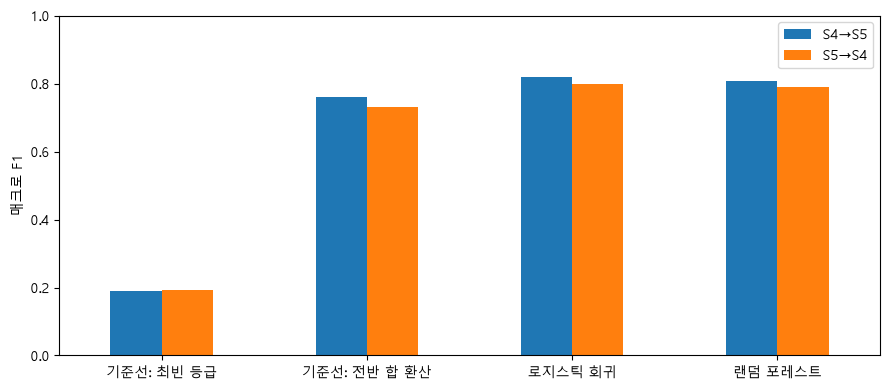

In [20]:
f1_cols = ["S4→S5 매크로 F1", "S5→S4 매크로 F1"]
ax = val_result[f1_cols].plot.bar(figsize=(9, 4), rot=0)  # 모델별로 검증 두 번을 나란히 표시
ax.set_xlabel("")
ax.set_ylabel("매크로 F1")
ax.set_ylim(0, 1)  # 매크로 F1의 범위 전체를 표시
ax.legend(["S4→S5", "S5→S4"])
plt.tight_layout()
plt.show()

In [16]:
final = make_models()["로지스틱 회귀"].fit(X_train, y_train)  # 학습 데이터(S4·S5) 전체로 다시 학습
ratio = (total[is_train] / X_train.sum(axis=1)).median()  # 총 기록 ÷ 전반 합 중앙값, 학습 데이터만 사용
est_total = X_test.sum(axis=1) * ratio

test_preds = {
    "기준선: 최빈 등급": np.full(len(y_test), y_train.mode()[0]),
    "기준선: 전반 합 환산": pd.cut(est_total, bins=edges, labels=edge_labels, right=False).astype(str).to_numpy(),
    "로지스틱 회귀": final.predict(X_test),
}
test_result = pd.DataFrame({
    name: {
        "정확도": accuracy_score(y_test, p),
        "매크로 F1": f1_score(y_test, p, labels=grade_labels, average="macro", zero_division=0),
    }
    for name, p in test_preds.items()
}).T.round(3)
print("시험(S6) 점수:")
print(test_result.to_string())

시험(S6) 점수:
                정확도  매크로 F1
기준선: 최빈 등급    0.402   0.191
기준선: 전반 합 환산  0.732   0.759
로지스틱 회귀       0.822   0.827


In [17]:
for tr in ["S4", "S5"]:  # 학습 시즌별로 로지스틱 회귀를 학습해 반복 횟수 확인
    m = make_pipeline(StandardScaler(), LogisticRegression())
    m.fit(X_all[season == tr], y_all[season == tr])
    print(tr, "반복 횟수:", m[-1].n_iter_)

S4 반복 횟수: [16]
S5 반복 횟수: [16]


### 결과
- 검증 점수에서 로지스틱 회귀가 두 방향, 두 지표 모두 가장 높음
- 로지스틱 회귀와 랜덤 포레스트의 차이는 S4→S5에서 0.013, S5→S4에서 0.009 (정확도·매크로 F1 동일)
- 로지스틱 회귀의 검증 정확도는 전반 합 환산 기준선보다 S4→S5에서 0.080, S5→S4에서 0.090 높음
- 검증 매크로 F1 그래프에서 최빈 등급 막대가 가장 낮고, 로지스틱 회귀 막대가 두 방향 모두 랜덤 포레스트 막대보다 약간 높음
- 학습 시즌별 반복 횟수 16회, 수렴 경고 없음
- 로지스틱 회귀를 학습 데이터(S4·S5) 전체로 다시 학습해 시험(S6)에서 정확도 0.822, 매크로 F1 0.827
- 시험(S6)에서 로지스틱 회귀의 정확도는 전반 합 환산 기준선보다 0.090, 최빈 등급 기준선보다 0.420 높음

**검증 점수 (시즌 2분할)**

| 모델 | S4→S5 정확도 | S4→S5 매크로 F1 | S5→S4 정확도 | S5→S4 매크로 F1 |
|---|---|---|---|---|
| 기준선: 최빈 등급 | 0.399 | 0.190 | 0.404 | 0.192 |
| 기준선: 전반 합 환산 | 0.735 | 0.760 | 0.704 | 0.732 |
| 로지스틱 회귀 | 0.815 | 0.820 | 0.794 | 0.800 |
| 랜덤 포레스트 | 0.802 | 0.807 | 0.785 | 0.791 |

**시험(S6) 점수**

| 모델 | 정확도 | 매크로 F1 |
|---|---|---|
| 기준선: 최빈 등급 | 0.402 | 0.191 |
| 기준선: 전반 합 환산 | 0.732 | 0.759 |
| 로지스틱 회귀 | 0.822 | 0.827 |

### 추정·한계
- 로지스틱 회귀와 랜덤 포레스트의 차이가 0.01 안팎이고 검증이 2번뿐이라, 이 차이가 의미 있는 크기인지는 구분 불가
- 로지스틱 회귀가 더 높은 원인은 구분 불가, 표준화 유무에 따른 비교는 하지 않음
- 전반 합 환산 기준선은 70분 미만·100분 이상 예측을 항상 틀린 것으로 계산하여, 모델과의 차이 중 이 영향이 얼마인지는 구분 불가
- 정답이 총 기록에서 만들어지고 입력인 전반 기록이 총 기록의 일부라서, 점수가 높게 나올 수 있음
- 정확도와 매크로 F1은 등급의 순서를 반영하지 않아, 한 등급 차이 오류와 두 등급 차이 오류를 구분하지 않음
- 설정값은 기본값만 사용, 다른 설정값은 비교하지 않았으며 선택 가이드 순서도의 첫 후보인 Linear SVC도 비교하지 않음
- 점수는 총 기록 70~100분 범위 안 기록에 한정됨
- 표준화 근거인 공식 문서의 조건(열의 분산이 자릿수 단위로 차이)에 입력 12열이 해당하는지는 확인하지 않음

### 한 줄 정리
- 시즌 2분할 검증에서 정확도·매크로 F1이 가장 높은 로지스틱 회귀를 골랐고, 시험(S6)에서 정확도 0.822, 매크로 F1 0.827로 전반 합 환산 기준선(0.732, 0.759)보다 높음

## 3. 오차 확인

**핵심:** 2절에서 고른 로지스틱 회귀의 시험(S6) 예측을 혼동행렬로 확인하여, 어느 등급을 어느 등급으로 틀렸는지 파악

### 작업 내용
- 대상: 2절에서 학습 데이터(S4·S5) 전체로 다시 학습한 로지스틱 회귀의 시험(S6) 예측
- 혼동행렬: 행은 실제 등급, 열은 예측 등급, 칸은 기록 수
- 혼동행렬 그래프: 칸 색이 진할수록 기록 수가 많고, 칸마다 기록 수 표시
- 등급 순서: 70~80분, 80~90분, 90~100분
- 등급 차이: 실제 등급과 예측 등급의 순서상 간격, 70~80분과 80~90분은 한 등급 차이, 70~80분과 90~100분은 두 등급 차이
- 예측 방향: 예측 등급이 실제보다 빠른 쪽이면 빠르게 예측, 느린 쪽이면 느리게 예측

### 확인 포인트
- 혼동행렬의 등급별 기록 수
- 실제 등급별로 틀린 기록 수
- 한 등급 차이와 두 등급 차이로 틀린 기록 수
- 빠르게 예측과 느리게 예측으로 틀린 기록 수
- 혼동행렬 그래프의 칸별 색 분포

In [18]:
pred = test_preds["로지스틱 회귀"]  # 2절에서 구한 시험(S6) 예측
cm = pd.DataFrame(
    confusion_matrix(y_test, pred, labels=grade_labels),
    index=[f"실제 {g}" for g in grade_labels],
    columns=[f"예측 {g}" for g in grade_labels],
)
print("시험(S6) 혼동행렬 (건):")
print(cm.to_string())
print("실제 등급별 틀린 기록 수(건):")
print((cm.sum(axis=1) - np.diag(cm.to_numpy())).to_string())

rank = {g: i for i, g in enumerate(grade_labels)}  # 등급 순서: 70~80=0, 80~90=1, 90~100=2
gap = pd.Series(pred).map(rank).to_numpy() - y_test.map(rank).to_numpy()  # 예측 - 실제, 음수는 빠르게 예측
print("등급 차이별 기록 수(건, 음수는 빠르게 예측, 양수는 느리게 예측):")
print(pd.Series(gap).value_counts().sort_index().to_string())

시험(S6) 혼동행렬 (건):
           예측 70~80  예측 80~90  예측 90~100
실제 70~80       3907       660          2
실제 80~90        577      5121        715
실제 90~100         5       884       4096
실제 등급별 틀린 기록 수(건):
실제 70~80      662
실제 80~90     1292
실제 90~100     889
등급 차이별 기록 수(건, 음수는 빠르게 예측, 양수는 느리게 예측):
-2        5
-1     1461
 0    13124
 1     1375
 2        2


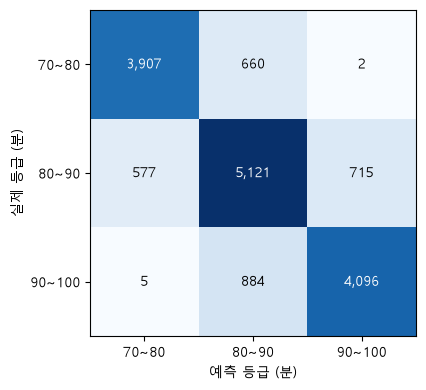

In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm.to_numpy(), cmap="Blues")  # 칸 색이 진할수록 기록 수가 많음
ax.set_xticks(range(len(grade_labels)), grade_labels)
ax.set_yticks(range(len(grade_labels)), grade_labels)
ax.set_xlabel("예측 등급 (분)")
ax.set_ylabel("실제 등급 (분)")
for i in range(len(grade_labels)):
    for j in range(len(grade_labels)):
        n = cm.iat[i, j]
        ax.text(j, i, f"{n:,}", ha="center", va="center",
                color="white" if n > cm.to_numpy().max() / 2 else "black")  # 진한 칸은 글자색 반전
plt.tight_layout()
plt.show()


### 결과
- 시험(S6) 15,967건 중 13,124건을 맞히고 2,843건을 틀림
- 실제 등급별 틀린 기록은 70~80분 662건, 80~90분 1,292건, 90~100분 889건
- 한 등급 차이로 틀린 기록 2,836건
- 두 등급 차이로 틀린 기록 7건
- 빠르게 예측으로 틀린 기록 1,466건
- 느리게 예측으로 틀린 기록 1,377건
- 혼동행렬 그래프에서 대각선 칸이 가장 진하고, 대각선에서 한 칸 떨어진 칸이 그다음이며, 두 칸 떨어진 칸(2건, 5건)이 가장 옅음

**시험(S6) 혼동행렬 (건)**

| 실제 \ 예측 | 70~80분 | 80~90분 | 90~100분 |
|---|---|---|---|
| 70~80분 | 3,907 | 660 | 2 |
| 80~90분 | 577 | 5,121 | 715 |
| 90~100분 | 5 | 884 | 4,096 |

**등급 차이와 예측 방향별 틀린 기록 (건)**

| 구분 | 방향 | 실제 → 예측 | 건수 |
|---|---|---|---|
| 한 등급 차이 | 빠르게 예측 | 80~90분 → 70~80분 | 577 |
| 한 등급 차이 | 빠르게 예측 | 90~100분 → 80~90분 | 884 |
| 한 등급 차이 | 느리게 예측 | 70~80분 → 80~90분 | 660 |
| 한 등급 차이 | 느리게 예측 | 80~90분 → 90~100분 | 715 |
| 두 등급 차이 | 빠르게 예측 | 90~100분 → 70~80분 | 5 |
| 두 등급 차이 | 느리게 예측 | 70~80분 → 90~100분 | 2 |

### 추정·한계
- 한 등급 차이 오류가 대부분인 원인은 구분 불가, 기록이 등급 경계에서 얼마나 떨어져 있는지는 확인하지 않음
- 빠르게 예측과 느리게 예측의 건수 차이가 의미 있는 크기인지, 그 원인은 구분 불가
- 80~90분에서 틀린 기록이 가장 많은 원인은 구분 불가
- 등급 경계 70·80·90분을 판단으로 정했으므로, 경계를 바꾸면 틀린 기록 수가 달라질 수 있음
- 시험(S6) 한 번의 결과이며, 다른 시즌에서도 같은 형태인지는 확인하지 않음

### 한 줄 정리
- 시험(S6)에서 틀린 2,843건 중 2,836건이 한 등급 차이이고, 빠르게 예측 1,466건, 느리게 예측 1,377건